In [378]:
print("Medical Insurance Cost Forecaster")

Medical Insurance Cost Forecaster


In [379]:
import zipfile

with zipfile.ZipFile('/content/archive (4).zip', 'r') as zip_ref:
    zip_ref.extractall('/content/insurance_data')

print("Dataset Extracted Successfully!")

Dataset Extracted Successfully!


In [380]:
import os

folder_path = "/content/insurance_data"

print(os.listdir(folder_path))

['insurance.csv']


In [381]:
import pandas as pd

file_path = "/content/insurance_data/insurance.csv"

df = pd.read_csv(file_path)

print(df.head())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [382]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (1338, 7)

Column Names:
Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [383]:
df.head(10)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


In [384]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [385]:
df.duplicated().sum()

np.int64(1)

In [386]:
df = df.drop_duplicates()

print("Duplicate data removed!")
print("New Dataset Shape:", df.shape)

Duplicate data removed!
New Dataset Shape: (1337, 7)


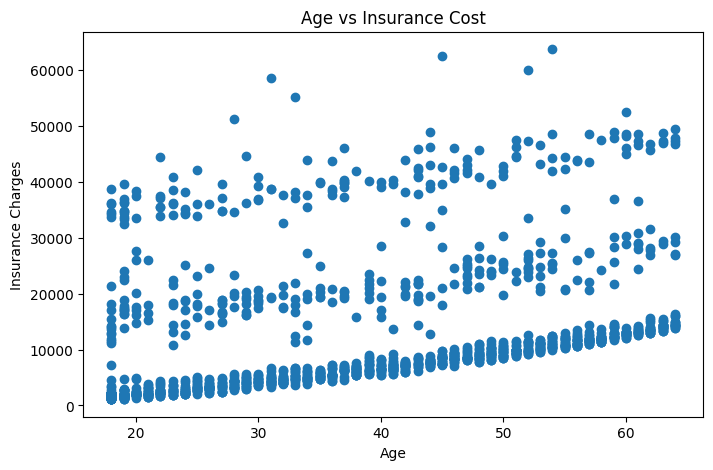

In [387]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(df['age'], df['charges'])

plt.xlabel("Age")
plt.ylabel("Insurance Charges")
plt.title("Age vs Insurance Cost")

plt.show()

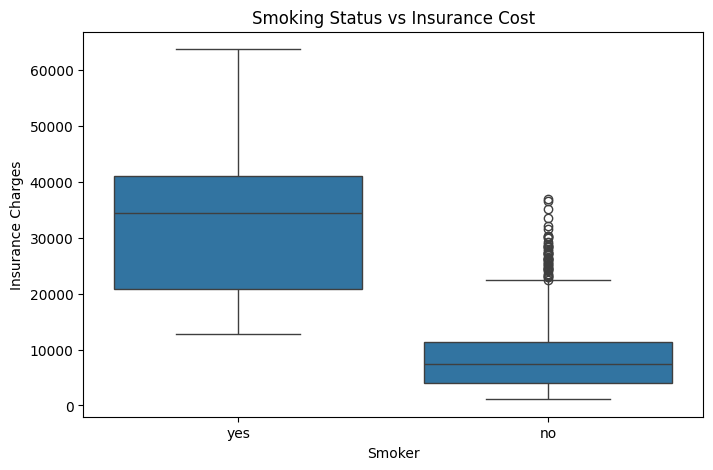

In [388]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

sns.boxplot(x='smoker', y='charges', data=df)

plt.title("Smoking Status vs Insurance Cost")
plt.xlabel("Smoker")
plt.ylabel("Insurance Charges")

plt.show()

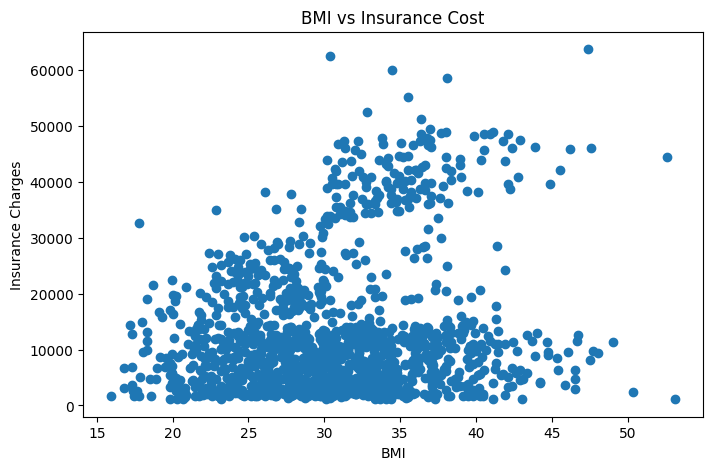

In [389]:
plt.figure(figsize=(8,5))

plt.scatter(df['bmi'], df['charges'])

plt.xlabel("BMI")
plt.ylabel("Insurance Charges")
plt.title("BMI vs Insurance Cost")

plt.show()

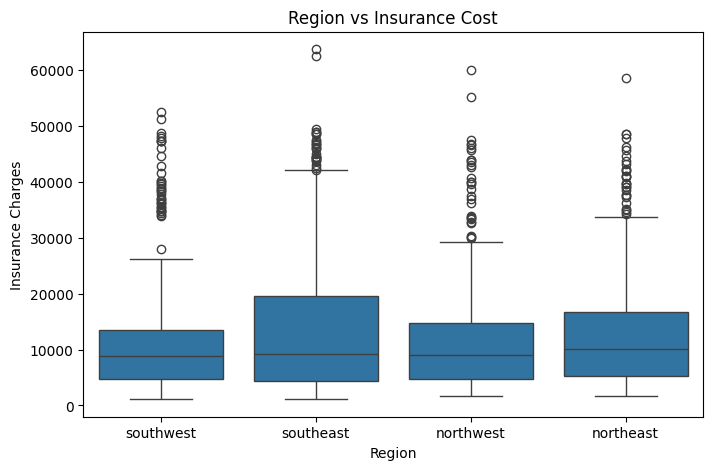

In [390]:
plt.figure(figsize=(8,5))

sns.boxplot(x='region', y='charges', data=df)

plt.title("Region vs Insurance Cost")
plt.xlabel("Region")
plt.ylabel("Insurance Charges")

plt.show()

In [391]:
df = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True, dtype=int)

print(df.head())

   age     bmi  children      charges  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0  16884.92400         0           1                 0   
1   18  33.770         1   1725.55230         1           0                 0   
2   28  33.000         3   4449.46200         1           0                 0   
3   33  22.705         0  21984.47061         1           0                 1   
4   32  28.880         0   3866.85520         1           0                 1   

   region_southeast  region_southwest  
0                 0                 1  
1                 1                 0  
2                 1                 0  
3                 0                 0  
4                 0                 0  


In [392]:
X = df.drop('charges', axis=1)

y = df['charges']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (1337, 8)
Target Shape: (1337,)


In [393]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1069, 8)
Testing Data: (268, 8)


In [394]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

print("Linear Regression Model Created Successfully!")

Linear Regression Model Created Successfully!


In [395]:
model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [396]:
y_pred = model.predict(X_test)

print("Predicted Insurance Costs:")
print(y_pred[:5])

Predicted Insurance Costs:
[ 8143.69388412  5737.11568259 14369.31487618 31745.51363586
  8962.38665706]


In [397]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("R2 Score:", r2)

Mean Absolute Error: 4177.045561036319
Mean Squared Error: 35478020.67523561
R2 Score: 0.8069287081198011


In [398]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

print("Random Forest Model Created Successfully!")

Random Forest Model Created Successfully!


In [399]:
rf_model.fit(X_train, y_train)

print("Random Forest Training Completed Successfully!")

Random Forest Training Completed Successfully!


In [400]:
rf_pred = rf_model.predict(X_test)

print("Predicted Insurance Costs:")
print(rf_pred[:5])

Predicted Insurance Costs:
[ 9293.3126237  8884.977884  11867.2743496 42030.1558487  6638.5088068]


In [401]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE:", rf_mae)
print("Random Forest MSE:", rf_mse)
print("Random Forest R2 Score:", rf_r2)

Random Forest MAE: 2637.9945481492537
Random Forest MSE: 22113000.538090803
Random Forest R2 Score: 0.8796611113027272


In [402]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "MSE": [mse, rf_mse],
    "R2 Score": [r2, rf_r2]
})

comparison

,Model,MAE,MSE,R2 Score
0,Linear Regression,4177.045561,3.547802e+07,0.806929
1,Random Forest,2637.994548,2.211300e+07,0.879661


In [403]:
new_person = pd.DataFrame([{
    "age": 30,
    "bmi": 25.5,
    "children": 1,
    "sex_male": 1,
    "smoker_yes": 0,
    "region_northwest": 0,
    "region_southeast": 1,
    "region_southwest": 0
}])

prediction = rf_model.predict(new_person)

print("Estimated Insurance Cost:", prediction[0])

Estimated Insurance Cost: 5177.2917715


In [404]:
print("========== INSURANCE COST PREDICTION ==========")
print("Person's Age: 30")
print("BMI: 25.5")
print("Children: 1")
print("Smoker: No")
print("-----------------------------------------------")
print(f"Estimated Insurance Cost: ${prediction[0]:,.2f}")
print("===============================================")

========== INSURANCE COST PREDICTION ==========
Person's Age: 30
BMI: 25.5
Children: 1
Smoker: No
-----------------------------------------------
Estimated Insurance Cost: $5,177.29


In [405]:
print("PROJECT: Medical Insurance Cost Forecaster")
print("------------------------------------------")
print("Dataset: Medical Cost Personal Dataset")
print("Machine Learning Models:")
print("1. Linear Regression")
print("2. Random Forest Regression")
print("------------------------------------------")
print("Model Evaluation Completed")
print("Insurance Cost Prediction Completed")
print("------------------------------------------")
print("Project Status: Completed Successfully!")

PROJECT: Medical Insurance Cost Forecaster
------------------------------------------
Dataset: Medical Cost Personal Dataset
Machine Learning Models:
1. Linear Regression
2. Random Forest Regression
------------------------------------------
Model Evaluation Completed
Insurance Cost Prediction Completed
------------------------------------------
Project Status: Completed Successfully!
